CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING
Objective: To group customers based on age, income and spending score.

Libraries imported successfully!

3. Customer Dataset


,Age,Annual_Income,Spending_Score
0,19,15,80
1,21,18,75
2,20,17,85
3,23,20,78
4,31,40,60
5,35,42,55
6,40,60,40
7,45,65,35
8,22,22,82
9,25,25,70


Dataset Shape: (20, 3)

4. Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Age             20 non-null     int64
 1   Annual_Income   20 non-null     int64
 2   Spending_Score  20 non-null     int64
dtypes: int64(3)
memory usage: 612.0 bytes

Missing Values:
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64

Dataset after Cleaning:


,Age,Annual_Income,Spending_Score
0,19,15,80
1,21,18,75
2,20,17,85
3,23,20,78
4,31,40,60
5,35,42,55
6,40,60,40
7,45,65,35
8,22,22,82
9,25,25,70



5. Feature Scaling Completed


,Age,Annual_Income,Spending_Score
0,-1.305168,-1.302211,1.119971
1,-1.137301,-1.177198,0.908256
2,-1.221235,-1.218869,1.331686
3,-0.969434,-1.093857,1.035285
4,-0.297964,-0.260442,0.273112


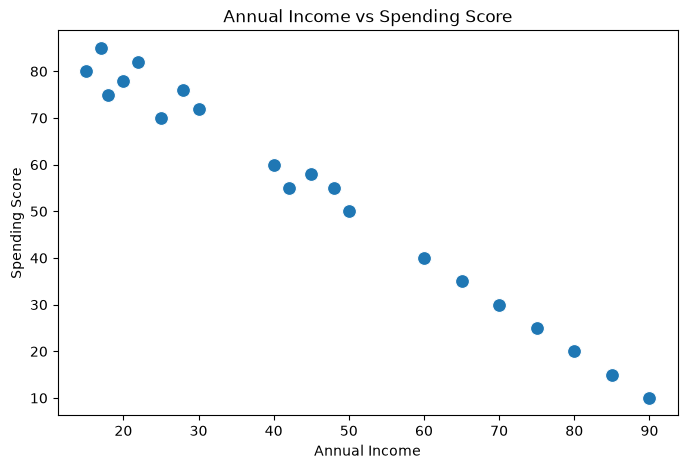

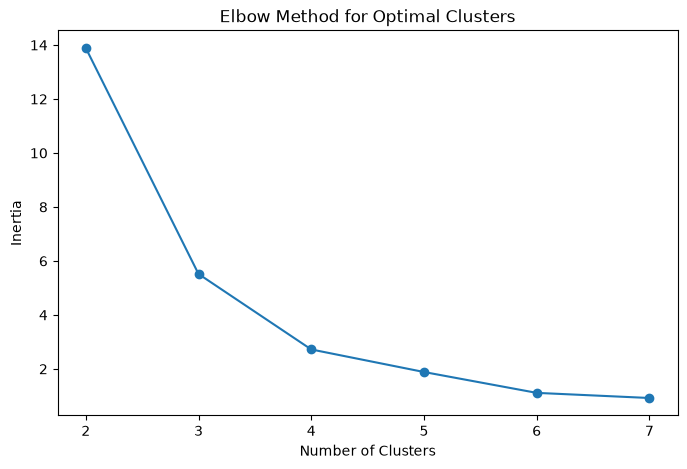


8. K-Means Clustering Results


,Age,Annual_Income,Spending_Score,KMeans_Cluster
0,19,15,80,1
1,21,18,75,1
2,20,17,85,1
3,23,20,78,1
4,31,40,60,2
5,35,42,55,2
6,40,60,40,2
7,45,65,35,0
8,22,22,82,1
9,25,25,70,1


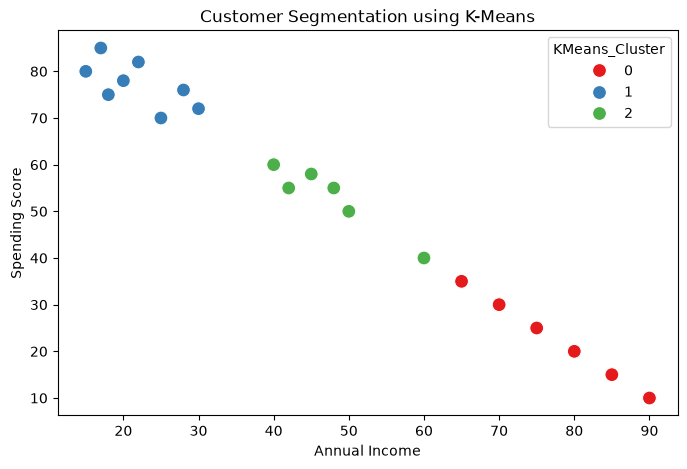


10. Hierarchical Clustering Results


,Age,Annual_Income,Spending_Score,KMeans_Cluster,Hierarchical_Cluster
0,19,15,80,1,1
1,21,18,75,1,1
2,20,17,85,1,1
3,23,20,78,1,1
4,31,40,60,2,2
5,35,42,55,2,2
6,40,60,40,2,0
7,45,65,35,0,0
8,22,22,82,1,1
9,25,25,70,1,1



11. Clustering Evaluation
K-Means Silhouette Score: 0.606
Hierarchical Silhouette Score: 0.6
K-Means performed better on this dataset.

12. Average Customer Details in Each K-Means Cluster


,Age,Annual_Income,Spending_Score
KMeans_Cluster,,,
0,50.0,77.50,22.50
1,23.0,21.88,77.25
2,34.5,47.50,53.00



13. Customers in Each Cluster
KMeans_Cluster
0    6
1    8
2    6
Name: count, dtype: int64


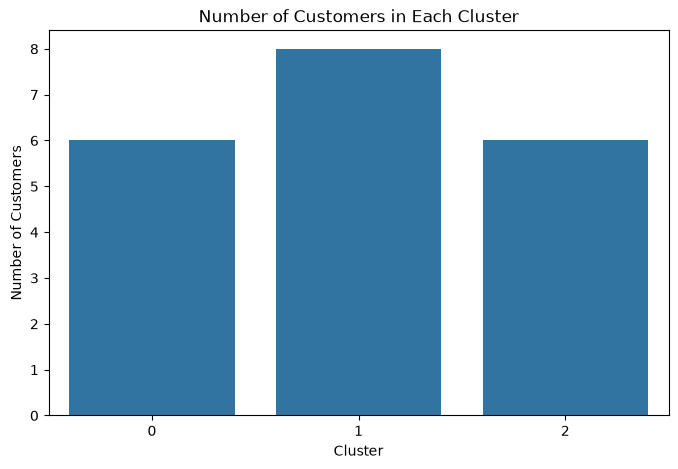


14. Results saved successfully!
File Name: customer_segmentation_results.csv

PROJECT CONCLUSION
1. Customer data was cleaned and standardized.
2. The Elbow Method was used to study cluster selection.
3. K-Means divided customers into three clusters.
4. Hierarchical Clustering was used for comparison.
5. Silhouette Scores were calculated for evaluation.
6. Customer groups can help understand spending behavior.

Mini Project Completed Successfully!


In [1]:

# LAB SHEET 07
# MINI PROJECT: Customer Segmentation using K-Means Clustering

# 1. Project Introduction
print("=" * 60)
print("CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING")
print("=" * 60)
print("Objective: To group customers based on age, income and spending score.")

# 2. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

print("\nLibraries imported successfully!")

# 3. Create Customer Dataset
data = {
    'Age': [19, 21, 20, 23, 31, 35, 40, 45, 22, 25,
            48, 50, 55, 60, 32, 28, 36, 42, 26, 33],
    'Annual_Income': [15, 18, 17, 20, 40, 42, 60, 65, 22, 25,
                      75, 80, 85, 90, 45, 30, 50, 70, 28, 48],
    'Spending_Score': [80, 75, 85, 78, 60, 55, 40, 35, 82, 70,
                       25, 20, 15, 10, 58, 72, 50, 30, 76, 55]
}

df = pd.DataFrame(data)

print("\n3. Customer Dataset")
display(df)

print("Dataset Shape:", df.shape)

# 4. Data Preprocessing
print("\n4. Dataset Information")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

df = df.drop_duplicates()
df = df.dropna()

print("\nDataset after Cleaning:")
display(df)

# 5. Feature Scaling
features = ['Age', 'Annual_Income', 'Spending_Score']

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[features])

print("\n5. Feature Scaling Completed")
display(pd.DataFrame(scaled_data, columns=features).head())

# 6. Visualize Original Customer Data
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Annual_Income',
                y='Spending_Score', s=100)
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

# 7. Find Optimal Clusters using Elbow Method
inertia_values = []
cluster_range = range(2, 8)

for k in cluster_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaled_data)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(cluster_range), inertia_values, marker='o')
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(list(cluster_range))
plt.show()

# 8. Apply K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(scaled_data)

print("\n8. K-Means Clustering Results")
display(df)

# 9. Visualize K-Means Clusters
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Annual_Income',
    y='Spending_Score',
    hue='KMeans_Cluster',
    palette='Set1',
    s=100
)
plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

# 10. Apply Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=3)
df['Hierarchical_Cluster'] = hierarchical.fit_predict(scaled_data)

print("\n10. Hierarchical Clustering Results")
display(df)

# 11. Evaluate Clustering Models
kmeans_score = silhouette_score(
    scaled_data, df['KMeans_Cluster']
)

hierarchical_score = silhouette_score(
    scaled_data, df['Hierarchical_Cluster']
)

print("\n11. Clustering Evaluation")
print("K-Means Silhouette Score:", round(kmeans_score, 3))
print("Hierarchical Silhouette Score:",
      round(hierarchical_score, 3))

if kmeans_score > hierarchical_score:
    print("K-Means performed better on this dataset.")
elif hierarchical_score > kmeans_score:
    print("Hierarchical Clustering performed better on this dataset.")
else:
    print("Both methods have equal Silhouette Scores.")

# 12. Cluster-wise Customer Analysis
print("\n12. Average Customer Details in Each K-Means Cluster")

summary = df.groupby('KMeans_Cluster')[
    features
].mean().round(2)

display(summary)

# 13. Number of Customers in Each Cluster
print("\n13. Customers in Each Cluster")
print(df['KMeans_Cluster'].value_counts().sort_index())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='KMeans_Cluster')
plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

# 14. Save Project Results
df.to_csv("customer_segmentation_results.csv", index=False)

print("\n14. Results saved successfully!")
print("File Name: customer_segmentation_results.csv")

# 15. Conclusion
print("\n" + "=" * 60)
print("PROJECT CONCLUSION")
print("=" * 60)
print("1. Customer data was cleaned and standardized.")
print("2. The Elbow Method was used to study cluster selection.")
print("3. K-Means divided customers into three clusters.")
print("4. Hierarchical Clustering was used for comparison.")
print("5. Silhouette Scores were calculated for evaluation.")
print("6. Customer groups can help understand spending behavior.")
print("\nMini Project Completed Successfully!")
